# Section 5 · Use the sampler primitive

Exam weight: 12% of C1000-179 · about 8 of the 68 questions

## Study path

**Core first pass:** Write Sampler PUBs, set shots and DD/twirling options, interpret sampling uncertainty, and retrieve per-register and parameter-sweep results.

- Core coding practice: **5.1–5.4**.
- Optional second pass: **5.5 (two-dimensional grid implementation), 5.6–5.7 (custom readout mitigation), the manual DD-pass demonstration, and the individually marked API questions.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Sampler options](#s5-core-2) · [Sampler theory and results](#s5-core-40) · [Review](#s5-core-80)

Official objectives
- 5.1 Set Sampler primitive options such as dynamical decoupling
- 5.2 Understand the theoretical background behind the Sampler primitive

Optional implementation extension (separate from objectives 5.1–5.2): bypass Runtime suppression and implement your own readout mitigation. The guide references error-management concepts; this extension goes further by implementing the correction algorithm.

Topics
- write valid Sampler PUBs and predict how many shots every PUB receives
- set any `SamplerV2` option in three ways, and spot option paths that do not exist (such as `resilience_level`)
- explain dynamical decoupling and Pauli twirling, and tell them apart from post-processing error mitigation
- walk the result tree `PrimitiveResult → SamplerPubResult → DataBin → BitArray`, including several registers and parameter sweeps
- relate shots to statistical error ($\propto 1/\sqrt{N}$) and explain the V1 → V2 change from quasi-distributions to per-shot samples
- switch Runtime suppression off and run your own readout-error mitigation

Built from the Qiskit Advocate KR study notebooks `1_Set_Sampler_options_KR.ipynb`, `2_Understand_Sampler_Theory.ipynb` and `Review/Practice_10_Qiskit_Primitives.ipynb`, and the QAMP 2025 tutorial (links in the Sources cell at the end).

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Parameter
from qiskit.primitives import BitArray
from qiskit.quantum_info import hellinger_fidelity
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2
from qiskit_ibm_runtime.options import SamplerOptions
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

plt.rcParams["figure.dpi"] = 90
# qiskit-ibm-runtime 0.40 emits an internal "max_circuits is deprecated" warning for fake backends; hide it
warnings.filterwarnings("ignore", message=".*max_circuits is deprecated.*")
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | "
      f"qiskit-ibm-runtime {qiskit_ibm_runtime.__version__}")

qiskit 2.0.3 | qiskit-aer 0.17.1 | qiskit-ibm-runtime 0.40.1


<a id="s5-core-2"></a>

## 5.1 Set Sampler options

### 5.1.1 One Sampler, local or on hardware

The exam's Sampler is `SamplerV2` from `qiskit_ibm_runtime`. `run(pubs, *, shots=None)` returns a job, and `job.result()` returns a `PrimitiveResult`. The same code runs in two places; only `mode` changes:

| Where | `mode=` | Notes |
|---|---|---|
| locally (this notebook) | `AerSimulator()` (ideal) or `AerSimulator.from_backend(FakeManilaV2())` (device model with noise) | local testing mode: no account; `options.simulator.seed_simulator` makes runs reproducible; default 1024 shots |
| IBM hardware | a backend from `QiskitRuntimeService`, or a `Session` / `Batch` on it | `options.default_shots` is `Unset`, so the service default applies (4096 per the `SamplerOptions` docstring) |

Qiskit also ships reference primitives with the same interface (for example `StatevectorSampler`), but this notebook uses only `SamplerV2`.

In [2]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.measure_all()          # adds a classical register named "meas"

backend = AerSimulator()
sampler = SamplerV2(mode=backend)
sampler.options.simulator.seed_simulator = 11   # reproducible local runs
pub_result = sampler.run([bell]).result()[0]
print("shots:", pub_result.metadata["shots"])
print("counts:", pub_result.data.meas.get_counts())

shots: 1024
counts: {'11': 517, '00': 507}


Local testing mode. Passing an `AerSimulator` as `mode` makes the Runtime primitive run locally. No account and no network are needed. `Session(backend=AerSimulator())` and `Batch(...)` also run locally, but no real session is created. In qiskit-ibm-runtime 0.40 the local runner forwards only the shot settings, `simulator.seed_simulator`, `simulator.noise_model` and `execution.meas_type`. Every other option, including dynamical decoupling and twirling, is dropped with the warning `Options {...} have no effect in local testing mode.` Circuits for a device model should still be transpiled to its target, exactly as on hardware (demo in 5.1.2).

On real hardware the same code only changes the `mode` (shown as text; this notebook has no credentials):

```python
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

# one time: QiskitRuntimeService.save_account(channel="ibm_quantum_platform",
#                                             token="<API key>", instance="<instance CRN or name>")
service = QiskitRuntimeService(channel="ibm_quantum_platform")
backend = service.least_busy(operational=True, simulator=False)

isa_bell = generate_preset_pass_manager(optimization_level=1, backend=backend).run(bell)
sampler = SamplerV2(mode=backend)            # or mode=Session(backend=backend) / Batch(backend=backend)
job = sampler.run([isa_bell])
print(job.job_id(), job.result()[0].data.meas.get_counts())
```

`SamplerV2` takes `mode=` (a backend, `Session` or `Batch`) and `options=`. The V1 keywords `backend=`, `circuits=` and `parameter_values=` and the V1 result field `quasi_dists` do not exist in V2.

### 5.1.2 Sampler PUBs and how many shots each PUB gets

A Sampler PUB (primitive unified bloc) is the tuple `(circuit, parameter_values, shots)`. Only the circuit is required.

| PUB | Meaning |
|---|---|
| `circuit` or `(circuit,)` | no parameters; shots come from `run()` or the defaults |
| `(circuit, parameter_values)` | bind an array of values; the result takes the array's shape (see 5.2.3) |
| `(circuit, parameter_values, shots)` | per-PUB shot count; use `None` as the values for a circuit without parameters |

Rules that the exam likes to probe:
- `run()` takes an iterable of PUBs: `sampler.run([qc])`, never `sampler.run(qc)`.
- `shots` is keyword-only: `run(pubs, *, shots=None)`.
- The circuit must measure into classical registers. The Sampler returns one data field per classical register; a circuit with no classical register returns an empty result and a warning.
- On a QPU the circuit must be an ISA circuit (transpiled to the target), otherwise the Runtime rejects it with `IBMInputValueError`. The demo below shows this check with a fake backend as `mode`. With `AerSimulator.from_backend(...)` as `mode` the Runtime skips the check, and Aer itself rejects gates outside the device basis with an `AerError`.

Shots precedence for each PUB (first match wins):

1. shots inside the PUB
2. `run(..., shots=N)`
3. Runtime only, when twirling is enabled: `num_randomizations × shots_per_randomization`
4. `options.default_shots`
5. the default: 1024 in local testing mode; the service default on IBM hardware

In [3]:
sampler = SamplerV2(mode=AerSimulator(), options={"default_shots": 300})

runs = {
    "options.default_shots only": sampler.run([bell]),
    "run(shots=200)": sampler.run([bell], shots=200),
    "PUB shots=100 and run(shots=200)": sampler.run([(bell, None, 100)], shots=200),
}
for label, job in runs.items():
    print(f"{label:34s} -> {job.result()[0].data.meas.num_shots} shots")

# Each PUB may carry its own shot count, even inside one job
res = sampler.run([(bell, None, 100), (bell, None, 50), bell]).result()
print("shots per PUB in one job:", [pub_result.data.meas.num_shots for pub_result in res])

options.default_shots only         -> 300 shots
run(shots=200)                     -> 200 shots
PUB shots=100 and run(shots=200)   -> 100 shots
shots per PUB in one job: [100, 50, 300]


In [4]:
from qiskit_ibm_runtime.exceptions import IBMInputValueError

# bell contains h and cx; FakeManilaV2's target only has cx, id, rz, sx, x (plus measure, delay, ...)
try:
    SamplerV2(mode=FakeManilaV2()).run([bell])          # a Runtime primitive on a fake backend checks ISA
except IBMInputValueError as err:
    print("IBMInputValueError:", str(err)[:75], "...")

isa_bell = generate_preset_pass_manager(optimization_level=1, backend=FakeManilaV2(),
                                        seed_transpiler=1).run(bell)
print("after transpiling:", dict(isa_bell.count_ops()))

IBMInputValueError: 'The instruction h on qubits (0,) is not supported by the target system. Ci ...
after transpiling: {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1, 'barrier': 1}


`(qc, 100)` is not "qc with 100 shots": the second PUB element is always the parameter values, so this raises a `ValueError`. Write `(qc, None, 100)` or `sampler.run([qc], shots=100)`.

Q5.1. `qc` is a measured circuit without parameters and `sampler = SamplerV2(mode=AerSimulator())`. Which call samples `qc` exactly 100 times?

A. `sampler.run(qc, shots=100)`

B. `sampler.run([qc], 100)`

C. `sampler.run([(qc, 100)])`

D. `sampler.run([(qc, None, 100)])`

<details>
<summary>Show answer</summary>

Answer: D

The third PUB element is the shot count, and `None` stands for "no parameter values". A passes a bare circuit where an iterable of PUBs is expected, so the sampler iterates over its instructions and raises `ValueError`. B fails with `TypeError` because `shots` is keyword-only. C looks right but the second element is read as parameter values, so it raises `ValueError`. (`sampler.run([qc], shots=100)` would also work.)

</details>

### Practice 5.1 — Shots precedence

With one `run()` call on `ex1_sampler`, sample `ex1_bell` 500 times and `ex1_ghz` with the sampler's `default_shots` (64). Store `job.result()` in `ex1_result`.

In [ ]:
ex1_sampler = SamplerV2(mode=AerSimulator(),
                        options={"default_shots": 64, "simulator": {"seed_simulator": 1}})
ex1_bell = QuantumCircuit(2)
ex1_bell.h(0)
ex1_bell.cx(0, 1)
ex1_bell.measure_all()
ex1_ghz = QuantumCircuit(3)
ex1_ghz.h(0)
ex1_ghz.cx(0, 1)
ex1_ghz.cx(1, 2)
ex1_ghz.measure_all()

# TODO: one run() call -> Bell with 500 shots, GHZ with the default shots
ex1_result = None

In [ ]:
# Run this cell to check your answer
assert ex1_result is not None, "store job.result() in ex1_result"
assert len(ex1_result) == 2, "expected two PUB results"
assert ex1_result[0].data.meas.num_shots == 500, "the Bell PUB should carry its own shots"
assert ex1_result[1].data.meas.num_shots == 64, "the GHZ PUB should fall back to default_shots"
assert set(ex1_result[0].data.meas.get_counts()) <= {"00", "11"}
assert set(ex1_result[1].data.meas.get_counts()) <= {"000", "111"}
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_sampler = SamplerV2(mode=AerSimulator(),
                        options={"default_shots": 64, "simulator": {"seed_simulator": 1}})
ex1_bell = QuantumCircuit(2)
ex1_bell.h(0)
ex1_bell.cx(0, 1)
ex1_bell.measure_all()
ex1_ghz = QuantumCircuit(3)
ex1_ghz.h(0)
ex1_ghz.cx(0, 1)
ex1_ghz.cx(1, 2)
ex1_ghz.measure_all()

ex1_result = ex1_sampler.run([(ex1_bell, None, 500), ex1_ghz]).result()
```

PUB-level shots beat everything else, and a PUB without shots falls back to `run(shots=...)` and then to `default_shots`. Passing `shots=64` to `run()` would also give 64 for the GHZ PUB, but the task asked for the default.

</details>

### 5.1.3 Setting options: three equivalent ways

`sampler.options` is a nested, validated dataclass (`SamplerOptions`). Every field starts as `Unset`, which means "let the service pick its default". You can set options

1. at construction, as a nested `dict` or a `SamplerOptions` object,
2. by attribute assignment on the dotted path,
3. in bulk with `options.update(...)`, which merges nested dicts.

Only `shots` can be passed to `run()`; everything else lives in `options`.

In [5]:
# 1) constructor: nested dict or SamplerOptions object
s1 = SamplerV2(mode=AerSimulator(),
               options={"default_shots": 2048,
                        "dynamical_decoupling": {"enable": True, "sequence_type": "XpXm"}})
s1b = SamplerV2(mode=AerSimulator(), options=SamplerOptions(default_shots=2048))

# 2) attribute assignment
s2 = SamplerV2(mode=AerSimulator())
s2.options.default_shots = 2048
s2.options.dynamical_decoupling.enable = True
s2.options.dynamical_decoupling.sequence_type = "XpXm"

# 3) bulk update (nested dicts are merged into the existing values)
s3 = SamplerV2(mode=AerSimulator())
s3.options.update(default_shots=2048, dynamical_decoupling={"enable": True, "sequence_type": "XpXm"})

for label, s in [("constructor", s1), ("attributes", s2), ("update()", s3)]:
    dd = s.options.dynamical_decoupling
    print(f"{label:12s} default_shots={s.options.default_shots}  dd.enable={dd.enable}  dd.sequence_type={dd.sequence_type}")
print("SamplerOptions object:", s1b.options.default_shots, "| untouched field:", s1b.options.twirling.enable_gates)

constructor  default_shots=2048  dd.enable=True  dd.sequence_type=XpXm
attributes   default_shots=2048  dd.enable=True  dd.sequence_type=XpXm
update()     default_shots=2048  dd.enable=True  dd.sequence_type=XpXm
SamplerOptions object: 2048 | untouched field: Unset


The `SamplerOptions` tree (defaults are the service defaults, applied when a field is `Unset`):

| Option | Sub-options (default) | Purpose |
|---|---|---|
| `default_shots` | int | shots when neither the PUB nor `run()` sets them |
| `dynamical_decoupling` | `enable` (False), `sequence_type` ("XX"), `extra_slack_distribution` ("middle"), `scheduling_method` ("alap"), `skip_reset_qubits` (False) | suppress errors on idle qubits |
| `twirling` | `enable_gates` (False), `enable_measure` (False), `num_randomizations` ("auto"), `shots_per_randomization` ("auto"), `strategy` ("active-accum") | Pauli twirling of 2-qubit gates and measurements |
| `execution` | `init_qubits` (True), `rep_delay` (backend default), `meas_type` ("classified") | how shots are executed and returned |
| `environment` | `log_level` ("WARNING"), `job_tags` (None), `private` (False) | job bookkeeping |
| `max_execution_time` | seconds | the job is cancelled if it runs longer |
| `simulator` | `seed_simulator`, `noise_model` (local testing mode only), `coupling_map`, `basis_gates` | simulator settings |
| `experimental` | dict | experimental server options |

Not Sampler options (they belong to `EstimatorOptions`): `resilience_level`, `resilience.*` (TREX, ZNE, PEA, PEC), `default_precision`, `seed_estimator`. The Runtime Sampler has no built-in error mitigation at all; its only noise-handling options are DD and twirling.

In [6]:
bad_settings = {
    "resilience_level = 1 (Estimator-only)": lambda s: setattr(s.options, "resilience_level", 1),
    "sequence_type = 'XY8' (not allowed)": lambda s: setattr(s.options.dynamical_decoupling, "sequence_type", "XY8"),
    "num_randomizations = 0 (must be >= 1)": lambda s: setattr(s.options.twirling, "num_randomizations", 0),
    "options.dynamical_decoupling = True": lambda s: setattr(s.options, "dynamical_decoupling", True),
}
for label, action in bad_settings.items():
    try:
        action(SamplerV2(mode=AerSimulator()))
        print(f"{label:40s} accepted")
    except Exception as err:
        print(f"{label:40s} {type(err).__name__}")

print()
s = SamplerV2(mode=AerSimulator(), options={"dynamical_decoupling": {"enable": True}})
s.options.dynamical_decoupling = {"sequence_type": "XY4"}          # assignment REPLACES the group
print("after assignment:", s.options.dynamical_decoupling.enable)

s = SamplerV2(mode=AerSimulator(), options={"dynamical_decoupling": {"enable": True}})
s.options.update(dynamical_decoupling={"sequence_type": "XY4"})    # update() MERGES
print("after update():  ", s.options.dynamical_decoupling.enable)

resilience_level = 1 (Estimator-only)    ValidationError
sequence_type = 'XY8' (not allowed)      ValidationError
num_randomizations = 0 (must be >= 1)    ValidationError
options.dynamical_decoupling = True      ValidationError

after assignment: Unset
after update():   True


Options are validated when you set them (pydantic `ValidationError`), not when the job is submitted. A misspelled path such as `options.dd.enable` fails immediately with an `AttributeError`, and an unknown top-level key in the constructor dict fails with a `ValidationError`.

V2 primitives do not transpile. The V1 options `optimization_level` and `transpilation.*` (for example `transpilation.skip_transpilation`) no longer exist, and setting them raises a `ValidationError`. Transpile yourself with `generate_preset_pass_manager(optimization_level=..., backend=backend).run(circuit)` and submit the ISA circuit.

> **Deeper API practice — optional on the first pass.** Replacing a whole nested option group is deeper API behaviour; setting individual option fields remains core.

Assigning a dict to a whole option group (`options.dynamical_decoupling = {...}`) builds a fresh group from that dict, so every sub-option you did not repeat goes back to `Unset`. Assign single fields, or use `options.update(...)`, which merges.

Q5.2. Which two constructor calls raise a `ValidationError`? Each is `SamplerV2(mode=AerSimulator(), options=...)` with the dict shown. (Select two.)

A. `{"default_shots": 2000}`

B. `{"resilience_level": 1}`

C. `{"dynamical_decoupling": {"enable": True, "sequence_type": "XY4"}}`

D. `{"twirling": {"num_randomizations": 0}}`

E. `{"environment": {"job_tags": ["exam"]}}`

<details>
<summary>Show answer</summary>

Answer: B, D

`resilience_level` is an Estimator option and does not exist on `SamplerOptions` (B), and `num_randomizations` must be at least 1 (D). `"XY4"` is one of the three allowed sequence types, and `default_shots` and `environment.job_tags` are ordinary Sampler options.

</details>

Q5.3. What does this print?

> **Deeper API practice — optional on the first pass.** The exact Unset values after nested-group replacement are additional debugging practice.

```python
sampler = SamplerV2(mode=backend,
                    options={"twirling": {"enable_gates": True, "num_randomizations": 16}})
sampler.options.twirling = {"enable_measure": True}
print(sampler.options.twirling.enable_gates, sampler.options.twirling.num_randomizations)
```

A. `True 16`

B. `True Unset`

C. `Unset Unset`

D. Nothing: the second line raises a `ValidationError`.

<details>
<summary>Show answer</summary>

Answer: C

Assigning a dict to the `twirling` group replaces it with a new `TwirlingOptions` built only from `{"enable_measure": True}`, so `enable_gates` and `num_randomizations` are back to `Unset`. A is what you would get with `sampler.options.update(twirling={"enable_measure": True})`, which merges. The assignment is valid, so no error is raised.

</details>

### Practice 5.2 — Configure a SamplerV2 for a hardware run

Configure `ex2_sampler` (local testing mode on an Aer model of `FakeManilaV2`; the same object would be used on a QPU) with:
- 2000 default shots
- dynamical decoupling enabled, sequence `XY4`, gates scheduled as soon as possible
- gate twirling enabled with 16 randomizations
- job tag `"sec5-practice"`
- `seed_simulator` = 1234

Use any of the three styles.

In [ ]:
ex2_sampler = SamplerV2(mode=AerSimulator.from_backend(FakeManilaV2()))
# TODO: set the options on ex2_sampler

In [ ]:
# Run this cell to check your answer
ex2_o = ex2_sampler.options
assert ex2_o.default_shots == 2000, "default_shots"
assert ex2_o.dynamical_decoupling.enable is True, "dynamical_decoupling.enable"
assert ex2_o.dynamical_decoupling.sequence_type == "XY4", "dynamical_decoupling.sequence_type"
assert ex2_o.dynamical_decoupling.scheduling_method == "asap", "dynamical_decoupling.scheduling_method"
assert ex2_o.twirling.enable_gates is True, "twirling.enable_gates"
assert ex2_o.twirling.num_randomizations == 16, "twirling.num_randomizations"
assert ex2_o.environment.job_tags == ["sec5-practice"], "environment.job_tags"
assert ex2_o.simulator.seed_simulator == 1234, "simulator.seed_simulator"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_sampler = SamplerV2(mode=AerSimulator.from_backend(FakeManilaV2()))
ex2_sampler.options.update(
    default_shots=2000,
    dynamical_decoupling={"enable": True, "sequence_type": "XY4", "scheduling_method": "asap"},
    twirling={"enable_gates": True, "num_randomizations": 16},
    environment={"job_tags": ["sec5-practice"]},
    simulator={"seed_simulator": 1234},
)
```

The option paths are `dynamical_decoupling.{enable, sequence_type, scheduling_method}`, `twirling.{enable_gates, num_randomizations}`, `environment.job_tags` and `simulator.seed_simulator`. The attribute style works just as well, for example `ex2_sampler.options.dynamical_decoupling.scheduling_method = "asap"`. In local testing mode DD and twirling are ignored (with a warning) when the job runs, but they are stored and would be sent to the service on hardware.

</details>

### 5.1.4 Dynamical decoupling (DD)

> **Study priority.** Core: why DD is used and how to enable it through Sampler options. The following Runtime example is core; the separate scheduling-pass reproduction is optional.

Problem. A qubit that waits while its neighbours run gates is not safe. Slow frequency drifts and always-on couplings (for example residual $ZZ$ crosstalk) keep rotating its phase, so the idle qubit dephases.

Idea. Fill every idle window with a pulse sequence whose ideal product is the identity, for example $X\cdot X = I$. A $\pi$ pulse in the middle of the window flips the sign of the phase that accumulates afterwards (a spin echo), so a slow error from the first half cancels in the second half.

| `sequence_type` | Pulses in an idle window ($\tau$ = spacing) | Comment |
|---|---|---|
| `"XX"` (default) | $\tau/2 - X - \tau - X - \tau/2$ | simplest echo |
| `"XpXm"` | $\tau/2 - (+X) - \tau - (-X) - \tau/2$ | opposite rotation senses, so pulse-amplitude errors cancel |
| `"XY4"` | $\tau/2 - X - \tau - Y - \tau - (-X) - \tau - (-Y) - \tau/2$ | alternates axes; more robust to pulse imperfections |

Other DD options: `scheduling_method` (`"alap"` default or `"asap"`, how gates are placed before idle windows are found), `extra_slack_distribution` (`"middle"` default or `"edges"`, where rounding slack from the discrete time step `dt` goes), and `skip_reset_qubits` (default `False`; skip idle windows right after initialization or reset, where the qubit is in $|0\rangle$).

Classification. DD changes how the circuit is physically executed. It needs no extra circuits and no post-processing, so it is error suppression, not error mitigation. It only helps circuits that contain idle periods, and it cannot be combined with dynamic circuits (the job is rejected with `IBMInputValueError`).

In [7]:
aer_manila = AerSimulator.from_backend(FakeManilaV2())   # device model: target, timing and noise

idle_qc = QuantumCircuit(3)
idle_qc.h(0)
idle_qc.cx(0, 1)
for _ in range(3):            # qubit 0 idles while qubits 1 and 2 work
    idle_qc.cx(1, 2)
    idle_qc.ry(0.4, 2)
idle_qc.cx(0, 1)
idle_qc.h(0)
idle_qc.measure_all()

pm_manila = generate_preset_pass_manager(optimization_level=1, backend=aer_manila,
                                         initial_layout=[0, 1, 2], seed_transpiler=1)
isa_idle = pm_manila.run(idle_qc)

sampler_dd = SamplerV2(mode=aer_manila)
sampler_dd.options.dynamical_decoupling.enable = True
sampler_dd.options.dynamical_decoupling.sequence_type = "XpXm"
sampler_dd.options.simulator.seed_simulator = 5

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    counts_dd = sampler_dd.run([isa_idle]).result()[0].data.meas.get_counts()
print(sampler_dd.options.dynamical_decoupling)
for w in caught:
    if "local testing mode" in str(w.message):
        print("Warning:", w.message)

DynamicalDecouplingOptions(enable=True, sequence_type='XpXm', extra_slack_distribution=Unset, scheduling_method=Unset, skip_reset_qubits=Unset)


> **Optional extension.** Reproduce DD with scheduling passes. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s5-resume-30). Later core code does not require this block.


ops before DD: {'rz': 10, 'sx': 8, 'cx': 5, 'measure': 3, 'barrier': 1}
ops after DD:  {'delay': 13, 'rz': 10, 'sx': 8, 'cx': 5, 'x': 4, 'measure': 3, 'barrier': 1}


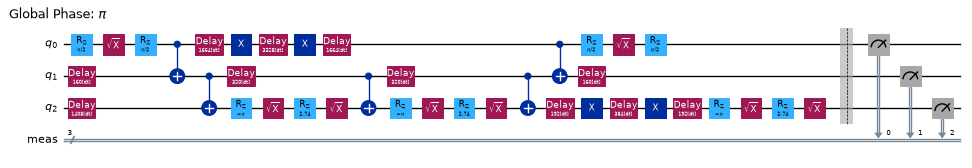

In [8]:
# Local testing mode dropped the DD request. On hardware the service schedules the ISA circuit
# and pads the idle windows. Qiskit's own scheduling passes reproduce that step:
from qiskit.circuit.library import XGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling

dd_pm = PassManager([
    ALAPScheduleAnalysis(target=aer_manila.target),                                     # scheduling_method="alap"
    PadDynamicalDecoupling(target=aer_manila.target, dd_sequence=[XGate(), XGate()]),   # sequence_type="XX"
])
isa_idle_dd = dd_pm.run(isa_idle)
print("ops before DD:", dict(isa_idle.count_ops()))
print("ops after DD: ", dict(isa_idle_dd.count_ops()))
isa_idle_dd.draw("mpl", idle_wires=False, fold=-1, scale=0.55)

On qubit 0 the long idle window became `Delay(τ/2) – X – Delay(τ) – X – Delay(τ/2)` (1664, 3328, 1664 `dt`). The same happened in a shorter window on qubit 2. The two `X` gates multiply to the identity, so the ideal circuit is unchanged; only the way noise acts during the wait changes. (Aer's noise model for a fake backend has no slow, coherent dephasing, so do not expect DD to improve simulated counts.)

<a id="s5-resume-30"></a>

If a question asks which Sampler option reduces decoherence of idle qubits, the answer is `dynamical_decoupling`. Minimal code: `sampler.options.dynamical_decoupling.enable = True`. Setting only `sequence_type` does not switch DD on, because `enable` stays at its default `False`.

Q5.4. A teammate runs the same ISA circuit twice on `SamplerV2(mode=AerSimulator.from_backend(FakeManilaV2()))` with the same `simulator.seed_simulator`: once with `dynamical_decoupling.enable = True`, once without. The counts are identical. What is the reason?

> **Deeper API practice — optional on the first pass.** The exact local-testing warning behaviour is an implementation detail. Know that local tests do not demonstrate Runtime suppression on a QPU.

A. Local testing mode does not apply DD or twirling; it drops those options with a "no effect in local testing mode" warning.

B. DD only takes effect when `sequence_type="XY4"` is also set.

C. DD also needs `resilience_level >= 1` on the Sampler.

D. DD pulses multiply to the identity, so DD can never change measured counts.

<details>
<summary>Show answer</summary>

Answer: A

The local runner forwards only shots, `seed_simulator`, `noise_model` and `meas_type`, so both runs are the same simulation with the same seed. D is the tempting distractor: the pulses are the identity only ideally; on hardware they change how idle-time noise acts, which is the whole point. B is wrong because every sequence type works once `enable=True`, and C is wrong because the Sampler has no `resilience_level`.

</details>

### 5.1.5 Pauli twirling

Problem. Coherent errors, such as a systematic over-rotation or residual $ZZ$ during a CX, add up in amplitude from layer to layer. Stochastic Pauli errors add up in probability. For the same per-gate error, coherent errors can therefore hurt much more in deep circuits.

Idea. Surround each two-qubit Clifford gate $U$ with random Paulis, $P$ before and $P' = U P U^\dagger$ after. Because $P'\,U\,P = U P U^\dagger U P = U$ (up to a global phase), the ideal circuit is unchanged. Averaged over many random choices, the noise channel of the gate becomes a Pauli (stochastic) channel: coherent errors turn into incoherent ones, which are easier to model and to mitigate.

Sampler twirling options (all default off or "auto"):
- `enable_gates`: twirl 2-qubit Clifford gates (CX, ECR, CZ). `enable_measure`: twirl measurements (random $X$ before the measurement, the classical bit is flipped back).
- `num_randomizations` × `shots_per_randomization`: each randomization is a separate circuit instance. With both on `"auto"`, `shots_per_randomization = max(64, ceil(shots/32))` and `num_randomizations = ceil(shots/shots_per_randomization)`. If you set both explicitly and give no PUB or `run()` shots, the product wins over `default_shots`: 32 × 100 = 3200 shots even with `default_shots=4096`. Shots given in the PUB or in `run()` take precedence, but per the IBM documentation the job fails if twirling is enabled with both values set and their product is smaller than those requested shots, because the shots cannot be spread over the randomizations.
- `strategy`: which qubits are twirled in each layer (`"active"`, `"active-accum"` default, `"active-circuit"`, `"all"`).

For the Estimator, `enable_measure` defaults to `True`, and per the IBM documentation resilience level 2 adds gate twirling. For the Sampler both default to `False`, so you switch them on yourself. Twirling is usually grouped with DD under suppression or noise tailoring: like DD, it changes which circuits are executed and needs no post-processing. On its own it can already reduce the impact of coherent noise, and it is also the basis of mitigation methods. TREX, ZNE, PEA and PEC post-process many results and are error mitigation (Estimator only).

In [9]:
from qiskit.circuit.library import CXGate
from qiskit.quantum_info import Clifford, Operator, Pauli

cx_op = Operator(CXGate())
print("P before CX -> P' after CX       (labels are little-endian: 'IX' = X on qubit 0 = control)")
for label in ["IX", "XI", "IZ", "ZI", "YY"]:
    before = Pauli(label)
    after = before.evolve(Clifford(CXGate()), frame="s")          # P' = CX P CX^dagger
    unchanged = Operator(after.to_matrix() @ cx_op.data @ before.to_matrix()).equiv(cx_op)
    print(f"   {label}  ->  {str(after):4s}   P'·CX·P == CX: {unchanged}")

sampler_tw = SamplerV2(mode=aer_manila, options={"twirling": {"enable_gates": True, "enable_measure": True,
                                                              "num_randomizations": 32,
                                                              "shots_per_randomization": 100}})
print(sampler_tw.options.twirling)

P before CX -> P' after CX       (labels are little-endian: 'IX' = X on qubit 0 = control)
   IX  ->  XX     P'·CX·P == CX: True
   XI  ->  XI     P'·CX·P == CX: True
   IZ  ->  IZ     P'·CX·P == CX: True
   ZI  ->  ZZ     P'·CX·P == CX: True
   YY  ->  -ZX    P'·CX·P == CX: True
TwirlingOptions(enable_gates=True, enable_measure=True, num_randomizations=32, shots_per_randomization=100, strategy=Unset)


Q5.5. Gate twirling places a random Pauli before a CX and a compensating Pauli after it. If the twirl applies $X$ to the control qubit before the CX, what must be applied after the CX so that the ideal operation is still a CX?

A. $X$ on the control only

B. $X$ on both the control and the target

C. $Z$ on the target only

D. $Z$ on both qubits

<details>
<summary>Show answer</summary>

Answer: B

$CX\,(X_c)\,CX^\dagger = X_c X_t$: an $X$ on the control is copied onto the target. Applying $X_cX_t$ after the gate therefore undoes it. A would leave a stray $X$ on the target. $Z$ propagates the other way (a $Z$ on the target becomes $Z_cZ_t$), which is the source of distractor D.

</details>

### 5.1.6 Execution, environment, time limit and simulator options

| Option path | Values (default) | Notes |
|---|---|---|
| `execution.init_qubits` | bool (`True`) | reset every qubit to $\lvert 0\rangle$ before each shot |
| `execution.rep_delay` | float (backend `default_rep_delay`) | delay between shots; only on backends with `dynamic_reprate_enabled` |
| `execution.meas_type` | `"classified"` (default), `"kerneled"`, `"avg_kerneled"` | classified → `BitArray`; kerneled → complex IQ array `(*pub_shape, num_shots, creg_size)`; avg_kerneled → `(*pub_shape, creg_size)` |
| `environment.job_tags` | list of str (`None`) | later: `service.jobs(job_tags=[...])` |
| `environment.log_level` | `"DEBUG"` … `"CRITICAL"` (`"WARNING"`) | server-side logging |
| `environment.private` | bool (`False`) | inputs deleted after the run, results deleted after the first read |
| `max_execution_time` | seconds (1–10 800 per the IBM documentation) | limit on system execution time; the job is cancelled when exceeded |
| `simulator.seed_simulator` | int | reproducible sampling on simulators and in local testing mode |
| `simulator.noise_model` | Aer `NoiseModel` or dict | local testing mode only |
| `simulator.coupling_map`, `simulator.basis_gates` | | simulator configuration |

In [10]:
from qiskit_aer.noise import NoiseModel, ReadoutError

readout_only = NoiseModel()                       # rows: prepared 0 / 1, columns: read 0 / 1
readout_only.add_all_qubit_readout_error(ReadoutError([[0.95, 0.05], [0.10, 0.90]]))

sampler_sim = SamplerV2(mode=AerSimulator())
sampler_sim.options.default_shots = 4000
sampler_sim.options.simulator.noise_model = readout_only
sampler_sim.options.simulator.seed_simulator = 42
sampler_sim.options.environment.job_tags = ["sec5", "readout-demo"]
sampler_sim.options.max_execution_time = 300

counts_1 = sampler_sim.run([bell]).result()[0].data.meas.get_counts()
counts_2 = sampler_sim.run([bell]).result()[0].data.meas.get_counts()
print(counts_1)
print("reproducible with seed_simulator:", counts_1 == counts_2)

{'00': 1774, '11': 1647, '10': 301, '01': 278}
reproducible with seed_simulator: True


`simulator.noise_model` and `simulator.seed_simulator` only matter for simulation; a QPU ignores them. And `execution.init_qubits=False` does not "turn off mitigation": it skips the reset between shots, so each shot starts from whatever the previous one left behind.

<a id="s5-core-40"></a>

## 5.2 Theory behind the Sampler primitive

### 5.2.1 What a Sampler estimates

A circuit prepares $|\psi\rangle$ and measures some qubits into classical bits. Each shot returns one bitstring $x$ with the Born-rule probability

$$p(x) = |\langle x|\psi\rangle|^2 \quad(\text{marginalised over unmeasured qubits}).$$

$N$ shots are $N$ independent samples. The natural estimate $\hat p(x) = n_x/N$ is unbiased, and its statistical error is

$$\sigma_{\hat p} = \sqrt{\frac{p(x)\,(1-p(x))}{N}} \;\le\; \frac{1}{2\sqrt{N}}.$$

So the error scales as $1/\sqrt{N}$: four times the shots halve it, and a 10× smaller error costs 100× the shots. More shots reduce statistical scatter only; they do not remove the bias caused by hardware noise.

Sampler vs Estimator. The Sampler returns raw samples of bitstrings, and you post-process them. The Estimator returns expectation values $\langle O\rangle$ with a standard error; you ask it for a precision, and it chooses the shots (about $1/\text{precision}^2$).

| | Sampler V1 (removed) | `SamplerV2` |
|---|---|---|
| input | `run(circuits, parameter_values, ...)` | `run([pubs], shots=...)` |
| output | `result.quasi_dists[i]`: a `QuasiDistribution` `{int: float}`, normalized, possibly negative after error mitigation | `result[i].data.<register>`: a `BitArray` of per-shot samples, one per classical register |
| noise handling | `resilience_level` | no mitigation; only DD and twirling, which change the executed circuits |

N=   64  mean p1=0.2498  observed std=0.0533  theory=0.0541


N=  256  mean p1=0.2513  observed std=0.0278  theory=0.0271


N= 1024  mean p1=0.2505  observed std=0.0132  theory=0.0135


N= 4096  mean p1=0.2502  observed std=0.0065  theory=0.0068


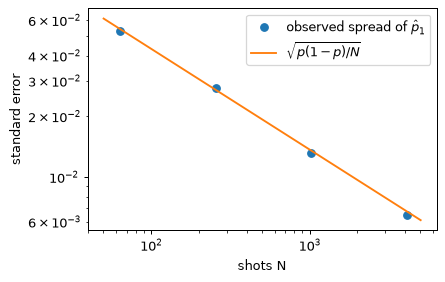

In [11]:
theta = Parameter("θ")
ry_qc = QuantumCircuit(1)
ry_qc.ry(theta, 0)
ry_qc.measure_all()
theta_quarter = 2 * np.arcsin(np.sqrt(0.25))          # p(1) = sin^2(θ/2) = 0.25

sampler = SamplerV2(mode=AerSimulator())
sampler.options.simulator.seed_simulator = 2026
repeats, shot_list, spread = 200, [64, 256, 1024, 4096], []
for n_shots in shot_list:
    # one PUB with the same θ repeated 200 times = 200 independent experiments of n_shots each
    ba = sampler.run([(ry_qc, np.full(repeats, theta_quarter))], shots=n_shots).result()[0].data.meas
    p1_hat = ba.bitcount().mean(axis=-1)               # fraction of '1' in each experiment
    spread.append(p1_hat.std(ddof=1))
    print(f"N={n_shots:5d}  mean p1={p1_hat.mean():.4f}  observed std={spread[-1]:.4f}  "
          f"theory={np.sqrt(0.25 * 0.75 / n_shots):.4f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.loglog(shot_list, spread, "o", label="observed spread of $\\hat p_1$")
n_grid = np.logspace(1.7, 3.7, 50)
ax.loglog(n_grid, np.sqrt(0.25 * 0.75 / n_grid), "-", label="$\\sqrt{p(1-p)/N}$")
ax.set_xlabel("shots N")
ax.set_ylabel("standard error")
ax.legend()
plt.show()

"The V2 Sampler returns a quasi-probability distribution" is a V1 statement. `SamplerV2` returns samples; you build probabilities yourself as `counts / num_shots`. Also, more shots never fix hardware bias: at 100 000 shots a noisy Bell state is measured very precisely, but still with the wrong probabilities.

Q5.6. An estimate of $p(x)\approx 0.5$ from 1000 shots has a standard error of about 0.016. Roughly how many shots give a standard error of about 0.004?

A. 4 000

B. 8 000

C. 16 000

D. 64 000

<details>
<summary>Show answer</summary>

Answer: C

The error scales as $1/\sqrt{N}$. A 4× smaller error needs $4^2 = 16$ times the shots: $\sqrt{0.25/16000} \approx 0.004$. A (4 000 shots) only halves the error, to about 0.008.

</details>

Q5.7. A V1 script used `result.quasi_dists[0]`. The circuit was built with `measure_all()`. Which V2 expression gives a normalized distribution over bitstrings?

A. `result[0].data.meas.get_counts()`

B. `result.quasi_dists[0].binary_probabilities()`

C. `result[0].data.quasi_dists`

D. `{k: v / result[0].data.meas.num_shots for k, v in result[0].data.meas.get_counts().items()}`

<details>
<summary>Show answer</summary>

Answer: D

V2 results hold per-shot samples in a `BitArray`. Dividing each count by `num_shots` gives the empirical probabilities. A returns raw counts that sum to the number of shots, not to 1. B and C use the V1 attribute `quasi_dists`, which neither `PrimitiveResult` nor `DataBin` has.

</details>

### Practice 5.3 — Shot budget

You want every probability in a histogram to have a standard error of at most 0.01, whatever the true probability is.
1. Store the smallest sufficient number of shots in `ex3_shots` (an `int`).
2. Store in `ex3_se_p01` the standard error you would then get for an outcome with $p = 0.1$.

In [ ]:
# TODO: smallest N with sqrt(p(1-p)/N) <= 0.01 for every p
ex3_shots = None
# TODO: standard error for p = 0.1 at N = ex3_shots
ex3_se_p01 = None

In [ ]:
# Run this cell to check your answer
assert ex3_shots is not None and ex3_se_p01 is not None, "fill in both values"
assert int(ex3_shots) == 2500, "use the worst case p = 0.5: 0.5/sqrt(N) <= 0.01"
assert abs(ex3_se_p01 - 0.006) < 1e-9
print("Correct!")

<details>
<summary>Show solution</summary>

```python
import math

ex3_shots = math.ceil((0.5 / 0.01) ** 2)          # worst case p = 0.5  ->  N = 2500
ex3_se_p01 = math.sqrt(0.1 * 0.9 / ex3_shots)      # 0.006
```

$p(1-p)$ is largest at $p = 0.5$, so $\sigma \le 0.5/\sqrt{N}$. Requiring $0.5/\sqrt N \le 0.01$ gives $N \ge 2500$. At that $N$ an outcome with $p=0.1$ has $\sigma = \sqrt{0.09/2500} = 0.006$, better than the worst case.

</details>

### 5.2.2 The result tree: `PrimitiveResult → SamplerPubResult → DataBin → BitArray`

```
PrimitiveResult                  result = job.result(); len(result) == number of PUBs
 ├─ metadata                     {'version': 2}
 └─ [i]  SamplerPubResult        result[i], in PUB order
      ├─ metadata                {'shots': ..., 'circuit_metadata': {...}}
      ├─ join_data(names=None)   merge several registers into one BitArray
      └─ data: DataBin           one field per classical register, named after the register
           ├─ meas: BitArray     measure_all() / measure_active() create register "meas"
           └─ c:    BitArray     QuantumCircuit(n, m) creates register "c"
```

| `BitArray` member | Returns |
|---|---|
| `num_shots`, `num_bits`, `shape` | shots per element, bits per shot, PUB shape |
| `get_counts(loc=None)` / `get_int_counts(loc=None)` | `{bitstring: count}` / `{int: count}`; with `loc=None` all elements of the shape are merged |
| `get_bitstrings(loc=None)` | per-shot bitstrings in shot order |
| `bitcount()` | Hamming weight of every shot |
| `slice_bits(indices)`, `slice_shots(indices)` | keep some bit positions (index 0 = rightmost bit) or some shots |
| `postselect(indices, selection)` | keep shots whose selected bits have the given values |
| `expectation_values(observables)` | $\langle O\rangle$ for diagonal observables such as `"ZZ"` |
| `BitArray.concatenate_bits([...])` | join registers shot by shot (the first array becomes the rightmost bits) |
| `array` | packed `uint8` data of shape `(*shape, num_shots, ceil(num_bits/8))` |

In [12]:
qr = QuantumRegister(3, "q")
alpha = ClassicalRegister(1, "alpha")
beta = ClassicalRegister(2, "beta")
two_reg = QuantumCircuit(qr, alpha, beta)
two_reg.h(0)
two_reg.cx(0, 1)                     # qubits 0 and 1: Bell pair
two_reg.x(2)                         # qubit 2: always 1
two_reg.measure(0, alpha[0])
two_reg.measure([1, 2], beta)        # qubit 1 -> beta[0], qubit 2 -> beta[1]

sampler = SamplerV2(mode=AerSimulator())
sampler.options.simulator.seed_simulator = 3
result = sampler.run([two_reg], shots=1000).result()
pub = result[0]
print(result)
print("fields:         ", list(pub.data))
print("alpha:          ", pub.data.alpha.get_counts())
print("beta:           ", pub.data["beta"].get_counts())
print("join_data():    ", pub.join_data().get_counts(), " <- read as beta | alpha")
print("beta bit 0 only:", pub.data.beta.slice_bits(0).get_counts())
print("first 5 shots:  ", pub.data.beta.get_bitstrings()[:5])

PrimitiveResult([SamplerPubResult(data=DataBin(alpha=BitArray(<shape=(), num_shots=1000, num_bits=1>), beta=BitArray(<shape=(), num_shots=1000, num_bits=2>)), metadata={'shots': 1000, 'circuit_metadata': {}})], metadata={'version': 2})
fields:          ['alpha', 'beta']
alpha:           {'1': 508, '0': 492}
beta:            {'11': 508, '10': 492}
join_data():     {'111': 508, '100': 492}  <- read as beta | alpha
beta bit 0 only: {'1': 508, '0': 492}
first 5 shots:   ['11', '10', '10', '11', '10']


The canonical V2 path is `result[0].data.meas.get_counts()` for a circuit built with `measure_all()`. For `QuantumCircuit(n, n)` plus explicit `measure(...)` calls, the register is `c`, so the path is `result[0].data.c.get_counts()`. The field is always named after the classical register.

Inside a register the rightmost character is bit 0 (little-endian), so `beta` reads `q2 q1`. `join_data()` and `concatenate_bits` put the first register in the rightmost positions, so the joined string reads `beta alpha` (the same order the legacy counts used, without the space). Field names come from the register names: `data.meas` exists only if a register called `meas` exists.

Q5.8. What does this print?

```python
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
qc.measure_all()
data = SamplerV2(mode=AerSimulator()).run([qc]).result()[0].data
print(list(data))
```

A. `['c', 'meas']`

B. `['meas']`

C. `['c']`

D. `['meas', 'c']`

<details>
<summary>Show answer</summary>

Answer: A

`QuantumCircuit(2, 2)` creates a register named `c`, and `measure_all()` adds a second register named `meas` (plus a barrier), so the `DataBin` has two fields in register order. B and C forget one of the registers. `measure_all()` adds its register instead of reusing `c` unless you call `measure_all(add_bits=False)`. D has the wrong order.

</details>

### Practice 5.4 — Read two classical registers

`ex4_qc` measures two data qubits into register `code` and a parity ancilla into register `flag`. From `ex4_pub`:
1. `ex4_code_counts`: counts of the `code` register only,
2. `ex4_joined_counts`: counts of both registers merged into one bitstring per shot.

Before you run the check, predict which bitstrings appear in each.

In [ ]:
ex4_code = ClassicalRegister(2, "code")
ex4_flag = ClassicalRegister(1, "flag")
ex4_qc = QuantumCircuit(QuantumRegister(3, "q"), ex4_code, ex4_flag)
ex4_qc.h(0)
ex4_qc.x(1)
ex4_qc.cx(0, 2)          # ancilla (qubit 2) collects the parity of qubits 0 and 1
ex4_qc.cx(1, 2)
ex4_qc.measure([0, 1], ex4_code)
ex4_qc.measure(2, ex4_flag)
ex4_sampler = SamplerV2(mode=AerSimulator(), options={"simulator": {"seed_simulator": 4}})
ex4_pub = ex4_sampler.run([ex4_qc], shots=1000).result()[0]

# TODO
ex4_code_counts = None
ex4_joined_counts = None

In [ ]:
# Run this cell to check your answer
assert ex4_code_counts is not None and ex4_joined_counts is not None, "fill in both dictionaries"
assert set(ex4_code_counts) == {"10", "11"} and sum(ex4_code_counts.values()) == 1000
assert set(ex4_joined_counts) == {"110", "011"}, "the first register (code) takes the rightmost bits"
assert ex4_joined_counts["110"] == ex4_code_counts["10"]
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_code = ClassicalRegister(2, "code")
ex4_flag = ClassicalRegister(1, "flag")
ex4_qc = QuantumCircuit(QuantumRegister(3, "q"), ex4_code, ex4_flag)
ex4_qc.h(0)
ex4_qc.x(1)
ex4_qc.cx(0, 2)
ex4_qc.cx(1, 2)
ex4_qc.measure([0, 1], ex4_code)
ex4_qc.measure(2, ex4_flag)
ex4_sampler = SamplerV2(mode=AerSimulator(), options={"simulator": {"seed_simulator": 4}})
ex4_pub = ex4_sampler.run([ex4_qc], shots=1000).result()[0]

ex4_code_counts = ex4_pub.data.code.get_counts()
ex4_joined_counts = ex4_pub.join_data().get_counts()
# equivalent: BitArray.concatenate_bits([ex4_pub.data.code, ex4_pub.data.flag]).get_counts()
```

Qubit 1 is always 1 and qubit 0 is random, so `code` (read `q1 q0`) is `10` or `11`. The flag is the parity $q_0 \oplus q_1$, so it is 1 exactly when $q_0 = 0$. `join_data()` places `code` (the first register) on the right and `flag` on the left: `1|10 = 110` and `0|11 = 011`.

</details>

### 5.2.3 Parameter sweeps and `BitArray` shapes

> **Study priority.** Core: distinguish the parameter axis from the PUB shape and retrieve one sweep point. The two-dimensional implementation exercise that follows is optional.

`parameter_values` has shape `(*pub_shape, num_parameters)`: the last axis lists one value per circuit parameter, in the order of `circuit.parameters` (sorted by name). The resulting `BitArray` has `shape == pub_shape`, and every element holds `num_shots` samples.

| Circuit parameters | `parameter_values` shape | `BitArray.shape` |
|---|---|---|
| 0 | none | `()` |
| 2 | `(2,)` (one binding) | `()` |
| 2 | `(10, 2)` | `(10,)` |
| 2 | `(4, 3, 2)` | `(4, 3)` |
| 1 | `(5,)`: a 1-D list for a one-parameter circuit is read as 5 bindings | `(5,)` |

A dict also works: `{theta: values}` or `{(a, b): values}`. PUBs in the same `run()` are independent: broadcasting happens inside a PUB, never across PUBs.

BitArray(<shape=(21,), num_shots=500, num_bits=1>)
counts at index 5 : {'1': 249, '0': 251}
counts with no loc: {'0': 5568, '1': 4932}  <- all 21 points merged


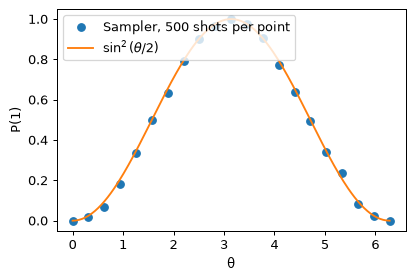

In [13]:
thetas = np.linspace(0, 2 * np.pi, 21)
sampler = SamplerV2(mode=AerSimulator())
sampler.options.simulator.seed_simulator = 7
sweep = sampler.run([(ry_qc, thetas)], shots=500).result()[0]
sweep_ba = sweep.data.meas
print(sweep_ba)
print("counts at index 5 :", sweep_ba.get_counts(5))
print("counts with no loc:", sweep_ba.get_counts(), " <- all 21 points merged")

p1 = sweep_ba.bitcount().mean(axis=-1)              # one value per sweep point, shape (21,)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(thetas, p1, "o", label="Sampler, 500 shots per point")
fine = np.linspace(0, 2 * np.pi, 200)
ax.plot(fine, np.sin(fine / 2) ** 2, "-", label="$\\sin^2(\\theta/2)$")
ax.set_xlabel("θ")
ax.set_ylabel("P(1)")
ax.legend(loc="upper left")
plt.show()

On a swept `BitArray`, `get_counts()` without `loc` silently merges every sweep point into one histogram. Use `get_counts(i)` (or a tuple index for multi-dimensional shapes), or vectorised helpers such as `bitcount()` that keep the shape.

Q5.9. A circuit has two parameters. It is run as `sampler.run([(qc, np.zeros((4, 3, 2)))], shots=50)`. What are `shape` and `num_shots` of `result[0].data.meas`?

A. shape `(4, 3, 2)`, `num_shots` 50

B. shape `(4, 3)`, `num_shots` 50

C. shape `(12,)`, `num_shots` 50

D. shape `()`, `num_shots` 600

<details>
<summary>Show answer</summary>

Answer: B

The last axis (size 2) holds one value per parameter, so the PUB shape is `(4, 3)`, and each of the 12 bindings gets its own 50 shots. A forgets that the last axis is consumed by the parameters. The shape is kept, not flattened (C), and shots are not pooled across bindings (D).

</details>

### Practice 5.5 — Two-dimensional parameter sweep

> **Optional extension.** Practice 5.5: implement a two-dimensional sweep. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s5-resume-62). Later core code does not require this block.

`ex5_qc` has parameters `a` (on qubit 0) and `b` (on qubit 1).
1. Build `ex5_values` with shape `(3, 4, 2)` so that `ex5_values[i, j] = (ex5_a[i], ex5_b[j])`.
2. Run one PUB with 400 shots on `SamplerV2(mode=AerSimulator())` and fill `ex5_p11` (shape `(3, 4)`) with the estimated probability of the bitstring `'11'` at every grid point.

In [ ]:
ex5_pa, ex5_pb = Parameter("a"), Parameter("b")
ex5_qc = QuantumCircuit(2)
ex5_qc.ry(ex5_pa, 0)
ex5_qc.ry(ex5_pb, 1)
ex5_qc.measure_all()
ex5_a = np.array([0, np.pi / 2, np.pi])
ex5_b = np.array([0, np.pi / 3, 2 * np.pi / 3, np.pi])

# TODO: parameter array of shape (3, 4, 2)
ex5_values = None
# TODO: run one PUB (400 shots) and estimate P('11') for every grid point -> shape (3, 4)
ex5_p11 = None

In [ ]:
# Run this cell to check your answer
assert ex5_values is not None and ex5_p11 is not None, "fill in both arrays"
assert np.shape(ex5_values) == (3, 4, 2), "parameter array must be (3, 4, 2)"
assert np.shape(ex5_p11) == (3, 4), "one probability per grid point"
ex5_theory = np.outer(np.sin(ex5_a / 2) ** 2, np.sin(ex5_b / 2) ** 2)
assert np.all(np.abs(ex5_p11 - ex5_theory) < 5 * np.sqrt(0.25 / 400) + 1e-12), "values far from theory"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex5_pa, ex5_pb = Parameter("a"), Parameter("b")
ex5_qc = QuantumCircuit(2)
ex5_qc.ry(ex5_pa, 0)
ex5_qc.ry(ex5_pb, 1)
ex5_qc.measure_all()
ex5_a = np.array([0, np.pi / 2, np.pi])
ex5_b = np.array([0, np.pi / 3, 2 * np.pi / 3, np.pi])

ex5_A, ex5_B = np.meshgrid(ex5_a, ex5_b, indexing="ij")
ex5_values = np.stack([ex5_A, ex5_B], axis=-1)       # last axis follows ex5_qc.parameters = [a, b]
ex5_ba = SamplerV2(mode=AerSimulator(), options={"simulator": {"seed_simulator": 5}}).run(
    [(ex5_qc, ex5_values)], shots=400).result()[0].data.meas
ex5_p11 = np.zeros(ex5_ba.shape)
for idx in np.ndindex(ex5_ba.shape):
    ex5_p11[idx] = ex5_ba.get_counts(idx).get("11", 0) / ex5_ba.num_shots
```

`np.meshgrid(..., indexing="ij")` plus `np.stack(..., axis=-1)` gives the `(3, 4, 2)` grid, and the `BitArray` comes back with shape `(3, 4)`. `get_counts(idx)` with a tuple index gives the histogram of one grid point. The ideal value is $P(11) = \sin^2(a/2)\,\sin^2(b/2)$, and the check allows five standard errors.

</details>

## 5.3 Bypass Runtime error handling and implement your own

> **Optional extension.** Implement readout-error mitigation yourself. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s5-resume-66). Later core code does not require this block.

The Runtime Sampler has no resilience options, so it never mitigates errors for you. Its only noise-handling features are DD and twirling, and both are off by default. When you compare your own technique with a raw baseline, switch them off explicitly so that the configuration is self-documenting. (For the Estimator the equivalent is `resilience_level=0` with DD and twirling off. On the Sampler `resilience_level` raises a `ValidationError`.)

We implement the classic client-side technique: readout-error mitigation with an assignment matrix.

$$\vec p_{\text{noisy}} = A\,\vec p_{\text{ideal}}, \qquad A_{ij} = P(\text{read } i \mid \text{prepared } j), \qquad \sum_i A_{ij} = 1 .$$

1. Calibrate: prepare every basis state $|j\rangle$, sample it, and fill column $j$ of $A$.
2. Correct: $\vec p_{\text{mit}} = A^{-1}\vec p_{\text{noisy}}$, then clip negative entries and renormalize (or use a constrained least-squares fit).

The full matrix needs $2^n$ calibration circuits and captures correlated readout errors. The tensored model assumes independent qubits and needs only 2 circuits (all zeros, all ones): $A \approx A_{n-1}\otimes\cdots\otimes A_1\otimes A_0$, with qubit 0 as the rightmost factor, the same order as the bitstrings.

In [14]:
raw_sampler = SamplerV2(mode=aer_manila, options={
    "dynamical_decoupling": {"enable": False},                    # no Runtime suppression
    "twirling": {"enable_gates": False, "enable_measure": False},
    "simulator": {"seed_simulator": 11},                          # local testing mode only
})   # local testing mode warns that the DD/twirling settings have no effect: expected here

n = 3
pm_ro = generate_preset_pass_manager(optimization_level=1, backend=aer_manila,
                                     initial_layout=[0, 1, 2], seed_transpiler=7)   # calibrate the qubits you use

ghz = QuantumCircuit(n)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
ghz.measure_all()

cal_circuits = []
for j in range(2**n):                   # prepare |j>: bit q of j -> X on qubit q (little-endian)
    cal = QuantumCircuit(n)
    for q in range(n):
        if (j >> q) & 1:
            cal.x(q)
    cal.measure_all()
    cal_circuits.append(cal)

shots_ro = 8000                         # same shots for all PUBs -> one job
res_ro = raw_sampler.run(pm_ro.run(cal_circuits + [ghz]), shots=shots_ro).result()

A = np.zeros((2**n, 2**n))
for j in range(2**n):
    for i, count in res_ro[j].data.meas.get_int_counts().items():
        A[i, j] = count / shots_ro
print("assignment matrix A (columns = prepared state):")
print(np.round(A, 3))

assignment matrix A (columns = prepared state):
[[0.856 0.027 0.017 0.001 0.091 0.004 0.002 0.   ]
 [0.029 0.856 0.001 0.019 0.003 0.08  0.    0.002]
 [0.019 0.001 0.854 0.034 0.002 0.    0.091 0.003]
 [0.001 0.017 0.032 0.847 0.    0.003 0.003 0.088]
 [0.09  0.004 0.002 0.    0.852 0.032 0.02  0.001]
 [0.003 0.092 0.    0.001 0.033 0.862 0.001 0.018]
 [0.002 0.    0.092 0.004 0.018 0.001 0.854 0.033]
 [0.    0.002 0.003 0.093 0.    0.02  0.028 0.855]]


Hellinger fidelity to the ideal GHZ state: raw 0.839  ->  mitigated 0.978


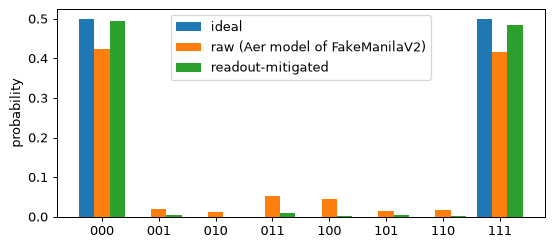

In [15]:
def mitigate(p_noisy, A):
    # Invert the readout model, then project back onto probability vectors
    x = np.linalg.solve(A, p_noisy)
    x = np.clip(x, 0, None)
    return x / x.sum()

def to_dict(vec, num_bits=n):
    return {format(i, f"0{num_bits}b"): float(v) for i, v in enumerate(vec) if v > 1e-12}

noisy_counts = res_ro[-1].data.meas.get_int_counts()
p_noisy = np.array([noisy_counts.get(i, 0) for i in range(2**n)]) / shots_ro
p_mit = mitigate(p_noisy, A)
ideal = {"000": 0.5, "111": 0.5}
print(f"Hellinger fidelity to the ideal GHZ state: raw {hellinger_fidelity(ideal, to_dict(p_noisy)):.3f}"
      f"  ->  mitigated {hellinger_fidelity(ideal, to_dict(p_mit)):.3f}")

labels = [format(i, f"0{n}b") for i in range(2**n)]
xpos = np.arange(2**n)
ideal_vec = np.array([ideal.get(b, 0) for b in labels])
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(xpos - 0.27, ideal_vec, 0.27, label="ideal")
ax.bar(xpos, p_noisy, 0.27, label="raw (Aer model of FakeManilaV2)")
ax.bar(xpos + 0.27, p_mit, 0.27, label="readout-mitigated")
ax.set_xticks(xpos, labels)
ax.set_ylabel("probability")
ax.legend()
plt.show()

The mitigated histogram removes most of the leakage into `001`, `011`, `100`, … that readout errors caused (in this device model qubit 2 has the worst readout, about 9%). What remains comes from CX errors and decoherence, which a readout model cannot undo.

Practical limits and alternatives:
- The full matrix costs $2^n$ calibration circuits and a $2^n\times 2^n$ inverse; the tensored model scales but misses correlated errors. Inversion also amplifies shot noise, which is why the result is clipped and renormalized.
- Calibrate on the same physical qubits and close in time to the experiment, since readout errors drift.
- Production tools: the `mthree` package (M3, matrix-free measurement mitigation) for sampler-style counts, or TREX through the Runtime Estimator (`resilience.measure_mitigation=True`, default at `resilience_level=1`) when you need expectation values.
- You can also do your own suppression: run `PadDynamicalDecoupling` (5.1.4) on your ISA circuit, then submit it with Runtime DD switched off.

The Sampler has no `resilience_level`. "Raw Sampler results" simply means DD and twirling off, which is already the default. If a question offers `options.resilience_level = 0` for a Sampler, that option raises a `ValidationError`.

### Practice 5.6 — Tensored readout model

> **Optional extension.** Part of the optional block above; skip its starter and check cells together.

Build the tensored model from the demo data. For every qubit `q`, fill the 2×2 matrix `ex6_A_q[q]`: column 0 from the all-zeros calibration `res_ro[0]` and column 1 from the all-ones calibration `res_ro[2**n - 1]` (hint: `.data.meas.slice_bits(q).get_int_counts()`). Combine the three matrices into the 8×8 `ex6_A_tensored` in the order that matches the bitstring index, and compute `ex6_p_mit = mitigate(p_noisy, ex6_A_tensored)`.

In [ ]:
ex6_A_q = []
for q in range(n):
    ex6_m = np.zeros((2, 2))
    # TODO: column 0 from res_ro[0], column 1 from res_ro[2**n - 1], using slice_bits(q)
    ex6_A_q.append(ex6_m)

ex6_A_tensored = None   # TODO: Kronecker product of the three 2x2 matrices (mind the order)
ex6_p_mit = None        # TODO

In [ ]:
# Run this cell to check your answer
assert ex6_A_tensored is not None and ex6_p_mit is not None, "fill in the TODOs"
assert np.shape(ex6_A_tensored) == (2**n, 2**n)
assert np.allclose(np.sum(ex6_A_tensored, axis=0), 1), "every column must sum to 1"
assert np.abs(ex6_A_tensored - A).max() < 0.02, "far from the full matrix: check the Kronecker order"
ex6_fid = hellinger_fidelity(ideal, to_dict(ex6_p_mit))
assert ex6_fid > 0.97, ex6_fid
print(f"tensored-model fidelity {ex6_fid:.3f}")
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_A_q = []
for q in range(n):
    ex6_m = np.zeros((2, 2))
    for prepared, cal_pub in [(0, res_ro[0]), (1, res_ro[2**n - 1])]:
        for measured, count in cal_pub.data.meas.slice_bits(q).get_int_counts().items():
            ex6_m[measured, prepared] = count / shots_ro
    ex6_A_q.append(ex6_m)

ex6_A_tensored = np.kron(ex6_A_q[2], np.kron(ex6_A_q[1], ex6_A_q[0]))   # qubit 0 = rightmost factor
ex6_p_mit = mitigate(p_noisy, ex6_A_tensored)
```

Index $i = b_2 b_1 b_0$ in binary, so qubit 0 must be the rightmost (fastest-changing) Kronecker factor: `kron(A2, kron(A1, A0))`. The reversed order `kron(A0, kron(A1, A2))` attaches qubit 2's large readout error to qubit 0. With this data it differs from the full matrix by about 0.06 and gives a noticeably lower fidelity (about 0.92 instead of 0.98). With only two calibration circuits the tensored model matches the full $2^3$-circuit matrix to within 0.01 here, because this noise model has no correlated readout errors.

</details>

### Practice 5.7 — Mitigate a counts dictionary

> **Optional extension.** Part of the optional block above; skip its starter and check cells together.

Write `ex7_mitigate_counts(counts, A)`. It receives a counts dict with bitstring keys (as returned by `get_counts()`, where some bitstrings may be missing) and an assignment matrix `A` (columns = prepared states). It returns `{bitstring: probability}` with non-negative values that sum to 1.

In [ ]:
def ex7_mitigate_counts(counts, A):
    # TODO: counts -> probability vector (index = int(bitstring, 2)) -> solve -> clip -> renormalize -> dict
    return None

In [ ]:
# Run this cell to check your answer
ex7_A0 = np.array([[0.97, 0.08], [0.03, 0.92]])
ex7_A1 = np.array([[0.90, 0.15], [0.10, 0.85]])
ex7_A = np.kron(ex7_A1, ex7_A0)
ex7_noisy = ex7_A @ np.array([0.5, 0, 0, 0.5])            # ideal Bell distribution through the readout model
ex7_counts = {format(i, "02b"): int(round(10000 * ex7_noisy[i])) for i in range(4)}
ex7_out = ex7_mitigate_counts(ex7_counts, ex7_A)
assert isinstance(ex7_out, dict), "return a dict"
assert abs(sum(ex7_out.values()) - 1) < 1e-9 and min(ex7_out.values()) >= 0
assert abs(ex7_out.get("00", 0) - 0.5) < 0.01 and abs(ex7_out.get("11", 0) - 0.5) < 0.01
ex7_one = ex7_mitigate_counts({"0": 100}, ex7_A0)          # inversion gives a negative P(1): clip it
assert abs(ex7_one.get("0", 0) - 1) < 1e-9 and ex7_one.get("1", 0) == 0
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex7_mitigate_counts(counts, A):
    num_bits = len(next(iter(counts)))
    total = sum(counts.values())
    p = np.zeros(2**num_bits)
    for bitstring, count in counts.items():
        p[int(bitstring, 2)] = count / total
    x = np.clip(np.linalg.solve(A, p), 0, None)
    x = x / x.sum()
    return {format(i, f"0{num_bits}b"): float(v) for i, v in enumerate(x) if v > 0}
```

Convert bitstrings to indices with `int(bitstring, 2)`; the rightmost character is bit 0, consistent with the matrix built above. A plain inverse can produce negative entries: in the second test, $A_0^{-1}(1, 0)^T = (1.034, -0.034)$. Clipping and renormalizing is the simplest way back to a valid distribution; a constrained least-squares fit gives the closest one.

</details>

<a id="s5-resume-62"></a>
<a id="s5-resume-66"></a>

Q5.10. Adapted from the KR study review set. Which statement about noise-handling techniques is wrong?

A. Pauli twirling turns an arbitrary noise channel into a Pauli channel, on average over randomizations.

B. TREX (twirled readout error extinction) mitigates measurement errors when estimating expectation values of Pauli observables.

C. Dynamical decoupling is an error-mitigation technique that removes coherent noise by post-processing the measured counts.

D. Zero-noise extrapolation is not guaranteed to give an unbiased estimate.

<details>
<summary>Show answer</summary>

Answer: C

DD is error suppression: it inserts identity pulse sequences into idle windows during execution and does no post-processing at all. A, B and D are correct descriptions. ZNE relies on an assumed extrapolation model, so it can remain biased (PEC is the method that is unbiased, at an exponential sampling cost).

</details>

<a id="s5-core-80"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Twelve mixed-depth practice questions. Begin with the unmarked questions before opening their answers.

R1. What does this print? (`qc` is a measured circuit without parameters.)

```python
sampler = SamplerV2(mode=AerSimulator(), options={"default_shots": 1000})
job = sampler.run([(qc, None, 200), qc], shots=500)
print([pub.data.meas.num_shots for pub in job.result()])
```

A. `[200, 1000]`

B. `[500, 500]`

C. `[200, 500]`

D. `[1000, 1000]`

<details>
<summary>Show answer</summary>

Answer: C

Precedence is PUB shots, then `run(shots=)`, then `default_shots`. The first PUB carries 200; the second has none, so it takes `run(shots=500)`. `default_shots=1000` would only be used if `run()` had no `shots` argument (that is option A's result).

</details>

R2. Which two techniques can be switched on through `SamplerV2` options? Both act on the circuits that are executed, with no post-processing of the results. (Select two.)

A. Twirled readout error extinction (TREX)

B. Dynamical decoupling

C. Zero-noise extrapolation (ZNE)

D. Pauli twirling of two-qubit gates

E. Probabilistic error cancellation (PEC)

<details>
<summary>Show answer</summary>

Answer: B, D

`options.dynamical_decoupling` and `options.twirling` are the only noise-handling groups in `SamplerOptions`. DD inserts identity pulse sequences into idle windows, and twirling runs randomized but ideally equivalent circuit instances. Neither needs post-processing, which is why both are usually grouped under suppression or noise tailoring. TREX, ZNE and PEC post-process results. They are error mitigation methods configured through `EstimatorOptions.resilience`, which the Sampler does not have.

</details>

R3. What does this print?

```python
qc = QuantumCircuit(3, 2)
qc.x(2)
qc.measure(0, 0)
qc.measure(2, 1)
sampler = SamplerV2(mode=AerSimulator())
print(sampler.run([qc], shots=100).result()[0].data.c.get_counts())
```

A. `{'10': 100}`

B. `{'01': 100}`

C. `{'100': 100}`

D. `{'001': 100}`

<details>
<summary>Show answer</summary>

Answer: A

Register `c` has 2 bits. Qubit 0 (in $|0\rangle$) goes to bit 0 and qubit 2 (in $|1\rangle$) goes to bit 1. Bit 0 is the rightmost character, so the string is `'10'`. B reverses the order (big-endian reading), and C and D wrongly print 3 bits although the register has only 2.

</details>

R4. What does this print?

```python
theta = Parameter("θ")
qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()
sampler = SamplerV2(mode=AerSimulator())
ba = sampler.run([(qc, [0, np.pi])], shots=100).result()[0].data.meas
print(ba.shape, ba.get_counts())
```

A. `(2,) {'0': 100}`

B. `(2,) {'0': 50, '1': 50}`

C. Nothing: `get_counts()` raises because the `BitArray` has shape `(2,)`.

D. `(2,) {'0': 100, '1': 100}`

<details>
<summary>Show answer</summary>

Answer: D

Each of the two bindings gets its own 100 shots: $\theta=0$ always gives `0` and $\theta=\pi$ always gives `1`. With `loc=None`, `get_counts()` merges all elements, so the total is 200 samples. Use `ba.get_counts(0)` or `ba.get_counts(1)` for a single point. A shows only the first point, and B splits one set of 100 shots instead of pooling two.

</details>

R5. `sampler = SamplerV2(mode=backend)`. Which snippet turns on dynamical decoupling with the XY4 sequence?

A.

```python
sampler.options.dynamical_decoupling = True
sampler.options.dynamical_decoupling.sequence_type = "XY4"
```

B.

```python
sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XY4"
```

C.

```python
sampler.options.dynamical_decoupling.sequence_type = "XY4"
```

D.

```python
sampler.options.dd.enable = True
sampler.options.dd.sequence_type = "XY4"
```

<details>
<summary>Show answer</summary>

Answer: B

`enable` and `sequence_type` are fields of the `dynamical_decoupling` group. A raises a `ValidationError` because the group expects a dict or a `DynamicalDecouplingOptions`, not a bool. C chooses the sequence but leaves `enable` at `Unset`, and the service default is `False`, so DD stays off. D fails because there is no `dd` attribute.

</details>

R6. On a QPU, `sampler.options.default_shots = 4096` and gate twirling is enabled with `num_randomizations=32` and `shots_per_randomization=100`. The job is submitted as `sampler.run([isa_circuit])`. How many shots does the PUB get?

A. 4096

B. 32

C. 3200

D. 131 072

<details>
<summary>Show answer</summary>

Answer: C

Per the `TwirlingOptions` documentation, the order is PUB shots, then `run(shots=)`, then the twirling product `num_randomizations × shots_per_randomization`, then `default_shots`. Neither of the first two is given, so 32 × 100 = 3200 shots are taken. D (32 × 4096) mixes up the two settings.

</details>

R7. Which two statements about Runtime local testing mode (qiskit-ibm-runtime 0.40) are true? (Select two.)

> **Deeper API practice — optional on the first pass.** These local-mode differences are useful for debugging the examples, rather than the first-pass Sampler workflow.

A. `SamplerV2(mode=AerSimulator.from_backend(FakeManilaV2()))` runs the job locally with a noise model built from the fake backend's calibration data.

B. Dynamical decoupling and twirling options are applied by the local simulator.

C. Setting `options.simulator.seed_simulator` makes repeated local runs return identical counts.

D. Local testing mode needs a saved IBM Quantum account.

E. A circuit containing `h` and `cx` gates can be passed to `SamplerV2(mode=FakeManilaV2())` without transpiling.

<details>
<summary>Show answer</summary>

Answer: A, C

A fake backend carries a snapshot of real calibration data; `AerSimulator.from_backend` turns it into a noise model plus the device's target, and the Runtime primitive runs on it locally. `seed_simulator` is one of the few options forwarded to the local run. B is false: DD and twirling are dropped with a "no effect in local testing mode" warning. D is false: no account or network is needed. E is false: with a fake backend as `mode` the Runtime checks the circuit against the target, and `h` is not in the basis, so it raises `IBMInputValueError`, as on hardware.

</details>

R8. `qc` contains gates but no measurements and no classical registers. What happens with `SamplerV2(mode=AerSimulator()).run([qc]).result()`?

A. It raises a `QiskitError` because Sampler circuits must contain measurements.

B. It returns the statevector amplitudes instead of counts.

C. It measures all qubits automatically and stores the samples in `data.meas`.

D. It runs, warns that the circuit has no output classical registers, and returns an empty `DataBin`.

<details>
<summary>Show answer</summary>

Answer: D

The Sampler returns one field per classical register. With no registers there is nothing to return, so you get a `UserWarning` and an empty `DataBin` rather than an exception. The Sampler never adds measurements for you (C) and never returns amplitudes (B).

</details>

R9. A single-qubit calibration gives the assignment matrix $A = \begin{pmatrix}0.95 & 0.10\\ 0.05 & 0.90\end{pmatrix}$ (columns = prepared state 0, 1). The measured distribution is $P(0)=0.60$, $P(1)=0.40$. What is the mitigated $P(0)$?

> **Deeper API practice — optional on the first pass.** Inverting a readout assignment matrix belongs to the optional mitigation extension.

A. 0.588

B. 0.600

C. 0.632

D. 0.550

<details>
<summary>Show answer</summary>

Answer: A

Solve $0.95\,p_0 + 0.10\,(1-p_0) = 0.60$: $0.85\,p_0 = 0.50$, so $p_0 = 0.588$. The $1\to 0$ flip rate (0.10) is larger than the $0\to 1$ rate (0.05), so readout moved net probability into `0`: $0.412 \times 0.10 \approx 0.041$ flows in and $0.588 \times 0.05 \approx 0.029$ flows out. The true $P(0)$ is therefore a little lower than the measured 0.60 (B). C ($0.60/0.95$) corrects only the $0\to 1$ loss and ignores the $1\to 0$ flips that inflate the count of `0`.

</details>

R10. Which value of `options.execution.meas_type` returns each classical register as a complex array of shape `(*pub_shape, creg_size)`, that is, IQ points averaged over shots?

> **Deeper API practice — optional on the first pass.** IQ-output array details are additional acquisition-mode practice; classified bit samples remain the first-pass focus.

A. `"avg_kerneled"`

B. `"kerneled"`

C. `"classified"`

D. `"level1"`

<details>
<summary>Show answer</summary>

Answer: A

`"kerneled"` keeps the shot axis, `(*pub_shape, num_shots, creg_size)`, and `"avg_kerneled"` averages it away. `"classified"` (the default) returns a `BitArray` of bits. `"level1"` is not an allowed value and raises a `ValidationError`.

</details>

R11. What does this print?

```python
alpha = ClassicalRegister(1, "alpha")
beta = ClassicalRegister(2, "beta")
qc = QuantumCircuit(QuantumRegister(3), alpha, beta)
qc.x(0)
qc.x(2)
qc.measure(0, alpha[0])
qc.measure([1, 2], beta)
pub = SamplerV2(mode=AerSimulator()).run([qc], shots=10).result()[0]
print(pub.join_data().get_counts())
```

A. `{'110': 10}`

B. `{'101': 10}`

C. `{'011': 10}`

D. Nothing: `join_data()` raises because the registers have different sizes.

<details>
<summary>Show answer</summary>

Answer: B

`alpha` holds qubit 0 → `'1'`. `beta` holds qubit 1 (bit 0) and qubit 2 (bit 1) → `'10'`. `join_data()` puts the first register (`alpha`) in the rightmost position: `'10' + '1' = '101'`. A is the order you get with `join_data(["beta", "alpha"])`. Registers of different sizes can be joined, since only the shot counts and shapes must match.

</details>

R12. You want raw results from a QPU through `SamplerV2` so that you can apply your own readout-error mitigation. Which configuration is correct?

> **Deeper API practice — optional on the first pass.** This configuration supports the optional custom-mitigation exercise.

A. `SamplerV2(mode=backend, options={"resilience_level": 0})`

B. `SamplerV2(mode=backend, options={"execution": {"init_qubits": False}})`

C. `SamplerV2(mode=backend, options={"environment": {"log_level": "DEBUG"}})`

D. `SamplerV2(mode=backend, options={"dynamical_decoupling": {"enable": False}, "twirling": {"enable_gates": False, "enable_measure": False}})`

<details>
<summary>Show answer</summary>

Answer: D

The Sampler's only built-in noise handling is DD and twirling, and D switches both off explicitly (they are also off by default). A raises a `ValidationError`, because `resilience_level` exists only for the Estimator. B stops the qubits from being reset between shots, which corrupts the data instead of making it raw. C only changes server-side logging.

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Running a Sampler

| Item | What to remember |
|---|---|
| Runtime class | `from qiskit_ibm_runtime import SamplerV2`; `SamplerV2(mode=..., options=...)` with `mode` = backend, `Session` or `Batch` |
| Local testing mode | `mode=AerSimulator()` or `AerSimulator.from_backend(FakeXxx())`; only shots, `seed_simulator`, `noise_model`, `meas_type` are used; DD and twirling are ignored with a warning; default 1024 shots |
| `run` | `sampler.run([pub, ...], shots=None)`: an iterable of PUBs; `shots` is keyword-only |
| PUB | `circuit` or `(circuit, parameter_values, shots)`; use `(qc, None, 100)` for shots without parameters |
| Shots precedence | PUB → `run(shots=)` → twirling `num_randomizations × shots_per_randomization` → `default_shots` → implementation default (1024 locally) |
| Mixed shots in one job | allowed: every PUB may carry its own shots |
| No measurements | empty `DataBin` plus a warning, not an exception |

Option paths under `sampler.options`

| Path | Values (default) |
|---|---|
| `default_shots` | int |
| `dynamical_decoupling.enable` / `.sequence_type` | bool (`False`) / `"XX"` (default), `"XpXm"`, `"XY4"` |
| `dynamical_decoupling.scheduling_method` / `.extra_slack_distribution` / `.skip_reset_qubits` | `"alap"` or `"asap"` / `"middle"` or `"edges"` / bool (`False`) |
| `twirling.enable_gates` / `.enable_measure` | bool (`False`) / bool (`False`) |
| `twirling.num_randomizations` / `.shots_per_randomization` / `.strategy` | int ≥ 1 or `"auto"` / int ≥ 1 or `"auto"` / `"active-accum"` (default), `"active"`, `"active-circuit"`, `"all"` |
| `execution.init_qubits` / `.rep_delay` / `.meas_type` | bool (`True`) / float / `"classified"`, `"kerneled"`, `"avg_kerneled"` |
| `environment.job_tags` / `.log_level` / `.private` | list / `"WARNING"` / bool |
| `max_execution_time` | seconds |
| `simulator.seed_simulator` / `.noise_model` / `.coupling_map` / `.basis_gates` | simulator only |
| Not on the Sampler | `resilience_level`, `resilience.*`, `default_precision`, `seed_estimator` (Estimator only); `optimization_level`, `transpilation.*` (V1 only; transpile yourself with `generate_preset_pass_manager`) → `ValidationError` |

Three ways to set options: `SamplerV2(mode=..., options={...})`, `sampler.options.a.b = v`, `sampler.options.update(a={...})` (merges). Assigning a dict to a whole group replaces the group.

Results

| Expression | Gives |
|---|---|
| `result[i]` | `SamplerPubResult` of PUB i |
| `result[i].data.<register>` | `BitArray` (`meas` from `measure_all()`, `c` from `QuantumCircuit(n, m)`) |
| `.get_counts(loc)` / `.get_int_counts()` / `.get_bitstrings()` | counts dict / integer-keyed counts / per-shot list |
| `.num_shots`, `.num_bits`, `.shape` | shots per element, bits per shot, PUB shape = `parameter_values.shape[:-1]` |
| `.slice_bits(i)`, `.postselect(i, v)`, `.bitcount()`, `.expectation_values(["ZZ"])` | bit selection, conditioning, Hamming weights, diagonal expectation values |
| `result[i].join_data()` | all registers joined per shot; the first register is the rightmost |

Theory

| Fact | |
|---|---|
| What the Sampler estimates | Born-rule probabilities $p(x) = \lvert\langle x\mid\psi\rangle\rvert^2$, via independent samples |
| Statistical error | $\sqrt{p(1-p)/N} \le 1/(2\sqrt N)$; 4× shots → half the error |
| V1 → V2 | `quasi_dists` (normalized, possibly negative) → per-shot `BitArray` per register |
| Suppression vs mitigation | DD (suppression) and twirling (noise tailoring, usually grouped with suppression) change the executed circuits, with no post-processing; TREX, ZNE, PEA, PEC post-process results (mitigation, Estimator only) |
| DIY readout mitigation | calibrate $A_{ij}=P(i\mid j)$, solve $A\vec p=\vec p_{\text{noisy}}$, clip and renormalize; tensored $A = A_{n-1}\otimes\cdots\otimes A_0$ |

## Sources and further reading

Qiskit Advocate KR study notebooks (synthesized here)
- [Section_5_Use_Sampler_Primitive](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_5_Use_Sampler_Primitive): `1_Set_Sampler_options_KR.ipynb`, `2_Understand_Sampler_Theory.ipynb`
- [Review](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Review): `Practice_10_Qiskit_Primitives.ipynb` (question 1 adapted as Q5.10)

QAMP 2025 textbook
- [qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial), folder `Section_5_Use_Sampler_Primitive` (`1_Set_Sampler_options.ipynb`, `2_Understand_Sampler_Theory.ipynb`)

Official IBM Quantum documentation
- [Introduction to primitives](https://quantum.cloud.ibm.com/docs/guides/primitives)
- [Runtime options overview](https://quantum.cloud.ibm.com/docs/guides/runtime-options-overview)
- [Sampler options](https://quantum.cloud.ibm.com/docs/guides/sampler-options)
- [Primitive inputs and outputs (PUBs)](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output)
- [Get started with Sampler](https://quantum.cloud.ibm.com/docs/guides/get-started-with-sampler)
- [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques)
- [Local testing mode](https://quantum.cloud.ibm.com/docs/guides/local-testing-mode)
- [qiskit-ibm-runtime API reference (SamplerV2, SamplerOptions)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime)
- Video: [An Introduction to Qiskit Runtime Primitives Version 2 (Chris Wood, QGSS 2024)](https://www.youtube.com/watch?v=OuYz02clnx4)

First-pass workflow review also consulted the open-source [Quantum Tokyo certification practice notebooks](https://github.com/quantum-tokyo/qiskit-certification-prep): execution-mode selection (Section 4), ISA preparation and default shots (Sections 5–6), and past-job retrieval (Section 7). Their questions were used as a style/reference check, not copied here; the official guide remains the scope reference.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [SamplerV2 (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/sampler-v2)
- [SamplerOptions (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/options-sampler-options)
- [Primitives (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/primitives)
- [BitArray (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.primitives.BitArray)
- [Get started with Sampler](https://quantum.cloud.ibm.com/docs/guides/get-started-with-sampler)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
